# Notebook 02 - Chapter 1 and 2

Below you find exercises for Chapter 1 and Chapter 2. These exercises will prepare you in particular for the obligatory mid-term tests. The purpose of the prepared code snippets below is to give you some helpful structure for coding by predefining some useful variable names, but you do not need to use these prepared code snippets and prepared variable names if you do not want to. Do not hestitate to use the function `help()` to print the documentation of the functions that you need. If you are stuck, please ask one of the supervisors present.
<br>

The binomial model is a useful tool to approximate option prices in the Black&ndash;Scholes model. Alternatively, option prices can be computed in the Black&ndash;Scholes model by numerically computing integrals. In the code snippet below, we define the variables $r$, $\sigma$, $T$, $K$ and $S(0)$ for the model.

In [1]:
import os
import marshal
import types
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.integrate import quad, solve_ivp
print(os.getcwd())

r = 0.02
sigma = 0.3
T = 1
K = 100
S0 = 120

/home/jovyan/my_materials


After running the import-statements above there should be a line displayed with `'/home/jovyan/my_materials'.`

<br><br>
## Step 1: Testing alternative parameterizations of the binomial model

As discussed in Exercise 01.1 on the first theoretical exercise sheet, it is possible to parameterize the binomial model in a different way so that $ud = c$ for some $c \in \mathbb{R}$ instead of $ud = 1$. Together with equations (1.1) and (1.2) from the lecture notes, this then changes the computation of the upward movement factor $u$ to \begin{equation} u = \beta + \sqrt{\beta^2 - c} \qquad \text{ with } \qquad \beta = \frac{1}{2}(c e^{-r\Delta t} + e^{(r + \sigma^2)\Delta t}) \end{equation}
A prominent way to use this different parameterization, which dates back to an idea of Leisen and Reimer in 1995, is to anchor the binomial tree at the strike $K$ by forcing $S(0) u^{\frac{M}{2}}d^{\frac{M}{2}} = K$. This corresponds to setting $c = (\frac{K}{S(0)})^{2 / M}$ in the equation $ud = c$.

**Task 1.1**: If not already done in Task 1.4 of the previous Notebook 01, write a function `european_CRR(g, S0, T, r, sigma, M)` that computes the price $V(0)$ of an option with terminal payoff $g(S(T))$ in the binomial model with `M` steps and volatility `sigma` by following the steps outlined in Tasks 1.1 to 1.3 of Notebook 01. If you already solved Task 1.4 of the previous week, you can copy your function there and paste it here.

In [2]:
def european_CRR(g1, S0, T, r, sigma, M):
    delta_t = T / M

    beta = 0.5 * (np.exp(-r * delta_t) + np.exp((r + sigma**2) * delta_t))
    u = beta + np.sqrt(beta**2 - 1)
    d = 1 / u
    q = (np.exp(r * delta_t) - d) / (u - d)

    # Build stock price tree
    S = np.zeros((M+1, M+1))
    for i in range(M+1):
        for j in range(i+1):
            S[j, i] = S0 * (u**j) * (d**(i - j))

    # Initialize option value
    V = np.zeros((M+1, M+1))

    # Apply arbitrary payoff function
    V[:, M] = g1(S[:, M])

    # Backward induction
    for i in range(M, 0, -1):
        V[:i, i-1] = np.exp(-r * delta_t) * (
            q * V[1:i+1, i] + (1 - q) * V[:i, i]
        )

    return V[0, 0]

K = 100
g1 = lambda S: np.maximum(S - K, 0)

price = european_CRR(g1, S0=120, T=1, r=0.02, sigma=0.3, M=200)
print(price)

### Uncomment and execute the following line only if you obtained no result:
# european_CRR1 = types.FunctionType(marshal.load(open('../shared_materials/objects/1_1_4.mar', 'rb')), globals())

# price1 = european_CRR1(g1, S0=100, T=1, r=0.05, sigma=0.2, M=50)
# print(price1)

26.81186123433826


**Task 1.2**: Modify your function `european_CRR` and write a new function `european_CRR_anchored(g, S0, T, r, sigma, M, c)` that takes the value $c \in \mathbb{R}$ from the parameterization equation $ud=c$ as an additional argument and computes the price $V(0)$ of an option with terminal payoff $g(S(T))$ in the binomial model with `M` steps, volatility `sigma` and parameterization $ud = c$.

In [10]:
def european_CRR_anchored(g1, S0, K, T, r, sigma, M, c):
    delta_t = T / M

    beta = 0.5 * (c * np.exp(-r * delta_t) + np.exp((r + sigma**2) * delta_t))
    u = beta + np.sqrt(beta**2 - c)
    d = c / u
    q = (np.exp(r * delta_t) - d) / (u - d)

    # Build stock price tree
    S = np.zeros((M+1, M+1))
    for i in range(M+1):
        for j in range(i+1):
            S[j, i] = S0 * (u**j) * (d**(i - j))

    # Initialize option value
    V = np.zeros((M+1, M+1))

    # Apply arbitrary payoff function
    V[:M+1, M] = g1(S[:M+1, M])

    # Backward induction
    for i in range(M, 0, -1):
        V[:i, i-1] = np.exp(-r * delta_t) * (
            q * V[1:i+1, i] + (1 - q) * V[:i, i]
        )

    return V[0, 0]

K = 100
g1 = lambda S: np.maximum(S - K, 0)


price = european_CRR_anchored(g1, S0=120, K = 100, T=1, r=0.02, sigma=0.3, M = 50, c = (K/S_arr[i]) ** (2 / 100))
print(price)

### Uncomment and execute the following line only if you obtained no result:
#european_CRR_anchored1 = types.FunctionType(marshal.load(open('../shared_materials/objects/2_1_2.mar', 'rb')), globals())
#price = european_CRR_anchored1(g1, S0=180, T=1, r=0.05, sigma=0.2, M=200, c = c_i)
#print(european_CRR_anchored1(g1, S0=120, K = 100, T=1, r=0.02, sigma=0.3, M = 50, c = (K/S_arr[i]) ** (2 / 100)))

26.947591650003083


We now want to compute the binomial model option prices corresponding to different values of the initial stock price $S(0)$.

**Task 1.3**: Define an array `S_arr` that contains 1000 equally spaced values of $S(0)$ between 20 and 300. Then, define a function `g_call(S)` that computes the payoff of a call option with strike $K = 100$ as a function of $S(T)$.

*Useful Python commands*: `np.linspace`, `np.maximum`

In [6]:
S_arr = np.linspace(20, 300, 1000)
# print(S_arr)
K = 100


def g_call(S):
    return np.maximum(S-K, 0)

call_option = g_call(120)
print(call_option)

### Uncomment and execute the following lines only if you obtained no result:
# S_arr1 = np.loadtxt('../shared_materials/objects/2_1_3.txt')
# print(S_arr1)

# print(np.array_equal(S_arr, S_arr1))
# g_call = types.FunctionType(marshal.load(open('../shared_materials/objects/2_1_3.mar', 'rb')), globals()) 

20


**Task 1.4**: Define an array `call_prices_CRR` of length 1000 and use a for-loop and your function `european_CRR` to fill it with the call prices in the CRR model with $M=100$ with $S(0)$ taking values in the array `S_arr` and all other input variables as before. Repeat the same procedure with your function `european_CRR_anchored` to compute call prices in the strike-anchored model ($c = (\frac{K}{S(0)})^{2 / M}$) and store them in an array `call_prices_CRR_anchored`.

In [7]:
call_prices_CRR = np.zeros(1000)
call_prices_CRR_anchored = np.zeros(1000)
print(len(call_prices_CRR))
# print(len(call_prices_CRR_anchored))

for i in range(1000):
    call_prices_CRR[i] = european_CRR(g1, S0 = S_arr[i], T = 1 , r = 0.02, sigma = 0.3, M = 100)
    call_prices_CRR_anchored[i] = european_CRR_anchored(g1, S0 = S_arr[i], K = 100, T = 1, r = 0.02, sigma = 0.3, M = 100, c = (K/S_arr[i]) ** (2 / 100))

#print(call_prices_CRR)
#print(call_prices_CRR_anchored)


### Uncomment and execute the following line only if you obtained no result:
call_prices_CRR1, call_prices_CRR1_anchored = np.loadtxt('../shared_materials/objects/2_1_4.txt')
#print(call_prices_CRR1)
#print(call_prices_CRR1_anchored)
#print(call_prices_CRR_anchored)

#print((np.round(call_prices_CRR, 10) == (np.round(call_prices_CRR1, 10))))
print((np.round(call_prices_CRR_anchored, 10) == (np.round(call_prices_CRR1_anchored, 10))))

1000
[ True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  Tr

We would now like to visualize the accuracy of the binomial model as an approximation to the Black-Scholes model with volatility $\sigma$. To do so, we first need to compute option prices via the Black-Scholes formula.

**Task 1.5**: Write a function `european_BS(t, St, K, T, r, sigma, call)` that computes the price $V(t)$ at time $t \in [0, T]$ of a European option with strike $K$ and terminal time $T$ in the Black&ndash;Scholes model with volatility $\sigma$ and risk-free interest rate $r$ via formula (2.23) in the lecture notes. If the argument `call` is equal to one, a call option price should be returned, if it is zero, a put option price should be returned.

*Useful Python commands*: `np.log`, `np.sqrt`, the standard normal cdf $\Phi$ can be accessed by the scipy.stats function `norm.cdf(...)`.

In [8]:
from scipy.stats import norm

def european_BS(t, St, K, T, r, sigma, call):

    d1 = (np.log(St/K) + (r + sigma ** 2 / 2) * (T - t)) / (sigma * np.sqrt(T - t))
    
    d2 = (np.log(St/K) + (r - sigma ** 2 / 2) * (T - t)) / (sigma * np.sqrt(T - t))

    # Put-Call-Parity
    if call == 1:
        return St * norm.cdf(d1) - K * np.exp(-r * (T - t)) * norm.cdf(d2)
        
    elif call == 0:
        return K * np.exp(-r * (T - t)) * norm.cdf(-d2) - St * norm.cdf(-d1)

print(european_BS(t = 0, St = 150, K = 23, T = 1, r = 0.02, sigma = 0.3, call = 0))


### Uncomment and execute the following line only if you obtained no result:
#european_BS1 = types.FunctionType(marshal.load(open('../shared_materials/objects/2_1_5.mar', 'rb')), globals())
#print(european_BS1(t = 0, St = 150, K = 1560, T = 1, r = 0.02, sigma = 0.3, call = 0))


3.4768383418338704e-10


**Task 1.6**: Use your function `european_BS` to compute the call option prices $V(0)$ at time $t = 0$ in the Black&ndash;Scholes model with $S(0)$ taking values in the array `S_arr` and all other input variables as before and store the option prices in an array `call_prices_BS`.

In [11]:
call_prices_BS = np.zeros(len(S_arr))
#print(len(call_prices_BS))

for i in range(len(S_arr)):
    call_prices_BS[i] = european_BS(t = 0, St= S_arr[i], K = 100, T = 1, r = 0.02, sigma = 0.3, call = 1)

#print(call_prices_BS)

### Uncomment and execute the following line only if you obtained no result:
call_prices_BS1 = np.loadtxt('../shared_materials/objects/2_1_6.txt')
#print(call_prices_BS1)

print((np.round(call_prices_BS, 10) == (np.round(call_prices_BS1, 10))))

[ True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  T

We are now ready to visualize the error $V_{\mathrm{Binomial}}(0) - V_{\mathrm{BS}}(0)$ of the binomial model, i.e. the difference between the binomial model option prices and the true Black&ndash;Scholes prices.

**Task 1.7**: Plot the difference of the binomial model prices stored in the array `call_prices_CRR` and the Black&ndash;Scholes prices stored in the array `call_prices_BS`. Repeat this for the binomial model prices with different parameterization stored in the array `call_prices_CRR_anchored`. Interpret your result using a comment. What are possible advantages/disadvantages of using the alternative parameterization?


<details>
  <summary>Result:</summary>

> <img src="../shared_materials/images/2_1_7.png" width="550"><details>
  <summary>Interpretation:</summary> The approximation error of the binomial model with $M = 100$ as an approximation of the Black&ndash;Scholes model is comparably large for the strike-anchored and the non-strike anchored version of the model. For initial stock prices above 65, the absolute approximation error is below 1% of the true Black-Scholes price, which is an acceptable accuracy. However, the approximation error of the non-strike anchored version has a strongly oscillating behaviour while the error of the strike-anchored version varies smoothly with the initial stock price. A resulting possible advantage of the strike-anchored version is that the calculation of sensitivities like the delta of an option (the first derivative of the option price with respect to the current stock price) will be much more accurate with the strike-anchored version than with the non-anchored version.

 </details>
</details>

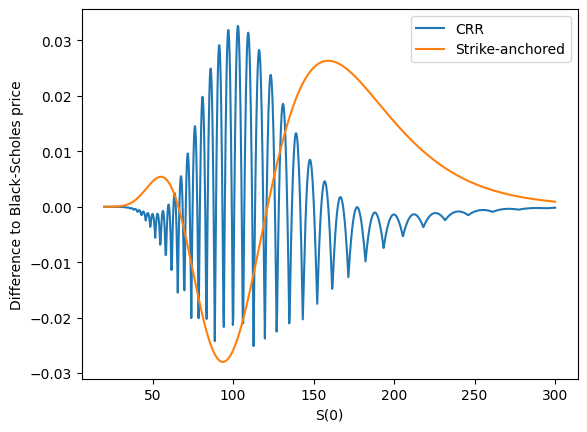

In [12]:
diff = np.zeros(len(call_prices_CRR))
diff1 = np.zeros(len(call_prices_CRR_anchored))

# print(diff)

for i in range(len(diff)):
    diff[i] = call_prices_CRR[i] - call_prices_BS[i]

for i in range(len(diff1)):
    diff1[i] = call_prices_CRR_anchored[i] - call_prices_BS[i]

#print(diff, diff1)

plt.plot(S_arr, diff, label = 'CRR')
plt.plot(S_arr, diff1, label = 'Strike-anchored')
plt.xlabel('S(0)')
plt.ylabel('Difference to Black-Scholes price')
plt.legend()
#plt.axhline(y= K * np.exp(-r * T), color = 'black', linestyle = '--', linewidth = 1)
#plt.axhline(y= 0, color = 'black', linestyle = '--', linewidth = 1)

plt.show()
# Interpretation: ...

In [13]:
print(call_prices_BS)

[1.36250384e-07 1.78076176e-07 2.31426771e-07 2.99116241e-07
 3.84556772e-07 4.91866402e-07 6.25992499e-07 7.92852666e-07
 9.99494894e-07 1.25427887e-06 1.56708042e-06 1.94952130e-06
 2.41522628e-06 2.98011013e-06 3.66269652e-06 4.48447146e-06
 5.47027368e-06 6.64872436e-06 8.05269892e-06 9.71984324e-06
 1.16931370e-05 1.40215066e-05 1.67604903e-05 1.99729577e-05
 2.37298868e-05 2.81112000e-05 3.32066618e-05 3.91168407e-05
 4.59541364e-05 5.38438758e-05 6.29254774e-05 7.33536879e-05
 8.52998906e-05 9.89534883e-05 1.14523361e-04 1.32239398e-04
 1.52354110e-04 1.75144313e-04 2.00912891e-04 2.29990637e-04
 2.62738168e-04 2.99547916e-04 3.40846195e-04 3.87095338e-04
 4.38795909e-04 4.96488984e-04 5.60758498e-04 6.32233664e-04
 7.11591444e-04 7.99559091e-04 8.96916745e-04 1.00450007e-03
 1.12320298e-03 1.25398034e-03 1.39785080e-03 1.55589957e-03
 1.72928132e-03 1.91922306e-03 2.12702700e-03 2.35407355e-03
 2.60182421e-03 2.87182454e-03 3.16570710e-03 3.48519442e-03
 3.83210191e-03 4.208340

<br><br>

## Step 2: Computing option prices via integration

Since we have explicit knowledge of the density of $S(T)$ in the Black&ndash;Scholes model, we can also price options with arbitrary payoffs by numerically evaluating integrals as detailed on p. 25 in the lecture notes. Integrals of the form $\int_a^b g(x) dx$ can be evaluated in Python using the scipy.integrate command `quad(g, a, b)[0]`. The lower and upper bounds `a` and `b` can also be set to `-np.inf` or `np.inf`.

**Task 2.1**: Write a function `european_integration(t, f, St, T, r, sigma)` that computes the price $V(t)$ of an option with terminal payoff $f(S(T))$ via the pricing-by-integration approach in the Black&ndash;Scholes model (see the formula for $V(t)$ at the bottom of p. 25). It should take the payoff function $f$ as an input argument.

In [14]:
from scipy.integrate import quad

def european_integration(t, f, St, T, r, sigma):
    def integrand(x):
        ST = St * np.exp((r - (sigma ** 2)/2) * (T - t) + sigma * np.sqrt(T - t) * x)
        return f_call(ST) * np.exp(-(x ** 2)/2)
    
    return np.exp(-r * (T - t)) / np.sqrt(2 * np.pi) * quad(integrand, -np.inf, np.inf)[0] # [0] meaning I only care about the answer, not the error

K = 100
f_call = lambda x: np.maximum(x - K, 0)

print(european_integration(0, f_call, St = 120, T = 1, r = 0.02, sigma = 0.3))

### Uncomment and execute the following line only if you obtained no result:
#european_integration1 = types.FunctionType(marshal.load(open('../shared_materials/objects/2_2_1.mar', 'rb')), globals())
#print(european_integration1(0, f_call, St = 120, T = 1, r = 0.02, sigma = 0.3))

26.803371401773845


**Task 2.2**: Write a function `f_call` that computes the terminal payoff of a European call option with strike $K = 100$ as a function of $S(T)$. Afterwards compute the price $V_{\mathrm{Int}}(0)$ of a European call option in the Black&ndash;Scholes model using all input variables as set in the beginning of this notebook. Store the output in a variable `call_price_int`.

*Useful Python commands*: `np.maximum`

In [15]:
#call_price_int = np.zeros(len(call_prices_BS))

#for i in range(len(call_prices_BS)):
#    call_price_int[i] = european_integration(0, f_call, St = S_arr[i], T = 1, r = 0.02, sigma = 0.3)

#K = 100
#f_call = lambda x: np.maximum(x - K, 0)

call_price_int = european_integration(0, f_call, St = 120, T = 1, r = 0.02, sigma = 0.3) # Only need V0
print(call_price_int)

### Uncomment and execute the following lines only if you obtained no result:
#f_call = types.FunctionType(marshal.load(open('../shared_materials/objects/2_1_3.mar', 'rb')), globals())
# call_price_int = 26.803371401773845

26.803371401773845


**Task 2.3**: Compute the some European call option price as in Task 2.2, but this time using your closed-form function `european_BS` from Task 1.5. Store the output $V_{\mathrm{BS}}(0)$ in a variable `reference_price_BS`. Afterwards, compute the relative absolute error $\frac{|V_{\mathrm{BS}}(0) - V_{\mathrm{Int}}(0)|}{V_{\mathrm{BS}}(0)}$ and print it to the console.

*Useful Python commands*: `np.abs`

In [21]:
reference_price_BS = european_BS(t = 0, St = 120, K = 100, T = 1, r = 0.02, sigma = 0.3, call = 1)

print(reference_price_BS)

rel_abs_error = np.abs((european_BS(t = 0, St = 120, K = 100, T = 1, r = 0.02, sigma = 0.3, call = 1)) - (european_integration(0, f_call, St = 120, T = 1, r = 0.02, sigma = 0.3))) / (european_BS(t = 0, St = 120, K = 100, T = 1, r = 0.02, sigma = 0.3, call = 1))

print(rel_abs_error)

### Uncomment and execute the following line only if you obtained no result:
# reference_price_BS = 26.803371450525006

26.803371450525006
1.8188443726216035e-09


<br><br>

## Step 3: Computation of power call prices and comparison of calculation times 

We now have gathered three different approaches to compute European option prices in the Black&ndash;Scholes model:

- **Using the Black&ndash;Scholes formula**: The closed-form formula gives the most accurate results and is very fast but is limited to simple payoff functions.
- **Using a binomial model**: This is completely flexible regarding the payoff function as long as the payoff is not path-dependent and it also handles American options easily. It is however just an approximation to the Black&ndash;Scholes model and $M$ must be chosen large in order to get accurate results.
- **Using pricing by integration**: This is completely flexible regarding the payoff function as long as the payoff is not path-dependent but it cannot handle American options. It is however faster and more accurate than the binomial model.

Our goal is now to test *how much faster* the pricing by integration approach is compared to the binomial model. We'd like to test this by pricing so-called *power-call options* that have a terminal payoff $f(S(T)) = (S(T)^\alpha - K)^+$ for some $\alpha > 0$ (see also Theoretical Exercise 03.2 on Homework Sheet 03).

**Task 3.1**: Set $\alpha = 1.2$. Then, write a function `f_powercall(S)` that calculates the payoff of the power call option as a function of $S(T)$.

*Useful Python commands*: `np.maximum`

In [22]:
alpha = 1.2

def f_powercall(St):
    x = np.maximum(St ** alpha - K, 0)
    return x
    
print(f_powercall(1340))

### Uncomment and execute the following line only if you obtained no result:
#f_powercall1 = types.FunctionType(marshal.load(open('../shared_materials/objects/2_3_1.mar', 'rb')), globals())
#print(f_powercall1(1340)) # 5556.21303135562

5556.21303135562


We now want to measure the calculation time of evaluating your function `european_integration` from Task 2.1. As detailed in the `Python Introduction.ipynb` notebook file, the execution time of a Jupyter Notebook cell can be measured by writing `%%time` at the beginning of the cell. We want to get an even more accurate measure of execution time by using instead `%%timeit -n 20 -r 3`: Writing this line at the beginning of the cell calculates the average calculation time over 20 independent executions of the cell code, then it repeats the whole loop 3 times and prints out the average and the standard deviation of the calculation time out of the 3 runs.

**Task 3.2**: Calculate the price $V(0)$ of the European power call with $\alpha=1.2$ by using your function `european_integration`. Write `%%timeit -n 20 -r 3` at the beginning of the cell to measure the execution time.

In [23]:
%%timeit -n 20 -r 3

def european_integration(t, f, St, T, r, sigma):
    def integrand(x):
        ST = St * np.exp((r - (sigma ** 2)/2) * (T - t) + sigma * np.sqrt(T - t) * x)
        return f_powercall(ST) * np.exp(-(x ** 2)/2)
    
    return np.exp(-r * (T - t)) / np.sqrt(2 * np.pi) * quad(integrand, -np.inf, np.inf)[0]

v0_1 = european_integration(0, f_powercall, St = 120, T = 1, r = 0.02, sigma = 0.3)


1.1 ms ± 11.6 μs per loop (mean ± std. dev. of 3 runs, 20 loops each)


**Task 3.3**: Repeat Task 3.2 but use the function `european_CRR` with `M=1000` instead of the function `european_integration`. Measure the execution time in the same way as in Task 3.2.

In [24]:
%%timeit -n 20 -r 3

def european_CRR(f_powercall, S0, T, r, sigma, M):
    delta_t = T / M

    beta = 0.5 * (np.exp(-r * delta_t) + np.exp((r + sigma**2) * delta_t))
    u = beta + np.sqrt(beta**2 - 1)
    d = 1 / u
    q = (np.exp(r * delta_t) - d) / (u - d)

    # Build stock price tree
    S = np.zeros((M+1, M+1))
    for i in range(M+1):
        for j in range(i+1):
            S[j, i] = S0 * (u**j) * (d**(i - j))

    # Initialize option value
    V = np.zeros((M+1, M+1))

    # Apply arbitrary payoff function
    V[:M+1, M] = g1(S[:M+1, M])

    # Backward induction
    for i in range(M, 0, -1):
        V[:i, i-1] = np.exp(-r * delta_t) * (
            q * V[1:i+1, i] + (1 - q) * V[:i, i]
        )

    return V[0, 0]

v0_2 = european_CRR(f_powercall, S0 = 120, T = 1, r = 0.02, sigma = 0.3, M = 1000)


179 ms ± 1.42 ms per loop (mean ± std. dev. of 3 runs, 20 loops each)


The function `european_CRR` as set up in Notebook 01 is not very optimized and is over 100 times slower than the `european_integration` method. It can however be optimized to yield faster results: Since only the final column of the stock price matrix in the binomial model is needed to calculate option payoff, it is unnecessary to calculate and store all the other columns.

**Task 3.4 (Optional)**:  Write a new function `european_CRR_optimized(g, S0, T, r, sigma, M)` that yields the same output as the function `european_CRR` but try to achieve a smallest possible execution time by optimizing the calculations within the function. Our own benchmark with `M=1000`: `3.55 ms ± 26.4 μs per loop (mean ± std. dev. of 10 runs, 100 loops each)`

In [27]:
%%timeit -n 20 -r 3

def european_CRR_optimized(g, S0, T, r, sigma, M): 
    delta_t = T / M

    beta = 0.5 * (np.exp(-r * delta_t) + np.exp((r + sigma**2) * delta_t))
    u = beta + np.sqrt(beta**2 - 1)
    d = 1 / u
    q = (np.exp(r * delta_t) - d) / (u - d)

    # Pre-discount factor
    discount = np.exp(-r * delta_t)
    p_up = discount * q
    p_down = discount * (1 - q)
    
    # 2. Vectorized terminal stock price calculation
    # S_T = S0 * u^j * d^(M - j) for j in range(M + 1)
    j = np.arange(M + 1)
    ST = S0 * (u ** j) * (d ** (M - j))
    
    # 3. Payoff at maturity (1D array)
    V = g(ST)
    
    # 4. Backward induction using a 1D vector in-place
    for i in range(M, 0, -1):
        V = p_up * V[1:i+1] + p_down * V[:i]
        
    return V[0]

v0_3 = european_CRR(f_powercall, S0 = 120, T = 1, r = 0.02, sigma = 0.3, M = 1000)


178 ms ± 1.43 ms per loop (mean ± std. dev. of 3 runs, 20 loops each)


<br><br>

## Step 4: Delta hedging a European call option on the DAX index

In the `data` subfolder of the `shared_materials` folder, you'll find a file called `DAX_sample.csv`. It contains daily close prices $S(t_i)$, $i \in \{1, \dots, 255\}$ of the German DAX index between 01 February 2023 and 31 January 2024 (255 trading days). 

**Task 4.1**: Import the time series of DAX prices from the file `DAX_sample.csv` and plot it.

*Useful Python commands*: `np.loadtxt`

<details>
  <summary>Result:</summary>

> <img src="./images/2_4_1.png" width="550">
</details>

255


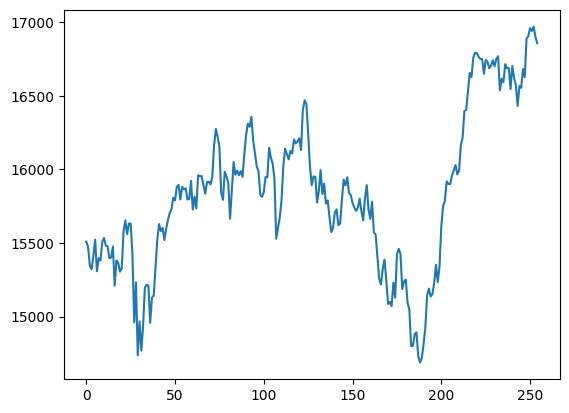

In [29]:
DAX = np.loadtxt("DAX_sample.csv", delimiter = ',')
plt.plot(DAX)

print(len(DAX))

Suppose that we want to hedge a European call option on the DAX with strike $K = 16000$ that is issued on 01 February 2023 and expires on 01 February 2024. That is, we want to set up a portfolio of the DAX and of a zero-coupon bond that tracks the European call option price over time as close as possible.

**Task 4.2**: Calculate the European call option prices $V(t)$, $t =  t_i \in \{0, \frac{1}{255}, \frac{2}{255}, \dots, \frac{254}{255}\}$ on the DAX index. For simplicity, use a Black&ndash;Scholes model with your function `european_BS` from Task 1.5. Set $r$ to the EURIBOR rate 0.03116 of 01 February 2023. The parameter $\sigma$ is supposed to be set to $\sqrt{255}$ times the empirical standard deviation of the daily log-returns $\log(S(t_{i + 1})) - \log(S(t_i)$ of the DAX timeseries. Store the option prices in an array `call_prices_DAX`.

*Useful Python commands*: `np.diff`, `np.log`, `np.std`, `np.sqrt`

In [30]:
def european_BS(t, St, K, T, r, sigma, call):

    d1 = (np.log(St/K) + (r + sigma ** 2 / 2) * (T - t)) / (sigma * np.sqrt(T - t))
    
    d2 = (np.log(St/K) + (r - sigma ** 2 / 2) * (T - t)) / (sigma * np.sqrt(T - t))

    # Put-Call-Parity
    if call == 1:
        return St * norm.cdf(d1) - K * np.exp(-r * (T - t)) * norm.cdf(d2)
        
    elif call == 0:
        return K * np.exp(-r * (T - t)) * norm.cdf(-d2) - St * norm.cdf(-d1)



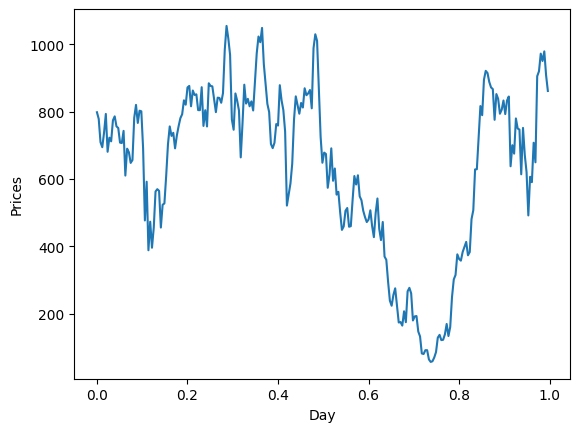

[ True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  T

In [39]:
euribor = 0.03316
log_return = np.diff(np.log(DAX), axis = 0) # axis = 0 → operate DOWN the rows (vertical direction) axis = 1 → operate ACROSS the columns (horizontal direction)
sigma1 = np.sqrt(255) * np.std(log_return)
t = np.arange(255) / 255
call_prices_DAX = np.zeros(255)

for i in range(len(call_prices_DAX)):
    call_prices_DAX[i] = european_BS(t = t[i], St= DAX[i], K = 16000, T = 1, r = 0.03316, sigma = sigma1, call = 1)

#print(call_prices_DAX)
plt.plot(t, call_prices_DAX)
plt.xlabel('Day')
plt.ylabel('Prices')
plt.show()

#print(call_prices_DAX)

### Uncomment and execute the following line only if you obtained no result:
call_prices_DAX1 = np.loadtxt('../shared_materials/objects/2_4_2.txt')
#print(call_prices_DAX1)

print((np.round(call_prices_DAX, 10) == (np.round(call_prices_DAX1, 10)))) # True

We are now ready to set up the hedging portfolio. In equation (2.29) in the lecture notes it is shown that a European option in the Black&ndash;Scholes model can be replicated by setting up a self-financing portfolio that holds $\partial_2 v(t, S(t))$ shares of the underlying at each point in time, where $v(t, S(t)) = V(t)$ is the option pricing function. The number $\partial_2 v(t, S(t))$ is called the *delta* of the option. For European call options in the Black&ndash;Scholes model, the delta can be easily calculated as \begin{equation} \partial_2 v(t, S(t)) = \Phi(d_1),\end{equation} where $d_1$ is as in equation (2.23).

**Task 4.3**: Write a function `delta_call_BS(t, St, K, T, r, sigma)` that calculates the delta of a European call option in the Black&ndash;Scholes model at time $t$.

*Useful Python commands*: `np.log`, `np.sqrt`, the standard normal cdf $\Phi$ can be accessed by the scipy.stats function `norm.cdf(...)`.

In [32]:
def delta_call_BS(t, St, K, T, r, sigma):
    delta1 = norm.cdf((np.log(St/K) + (r + sigma ** 2 / 2) * (T - t)) / (sigma * np.sqrt(T - t)))
    return delta1
        
print(delta_call_BS(t = 0, St = 120, K = 100, T = 1, r = 0.02, sigma = 0.3))

### Uncomment and execute the following line only if you obtained no result:
delta_call_BS1 = types.FunctionType(marshal.load(open('../shared_materials/objects/2_4_3.mar', 'rb')), globals())
print(delta_call_BS1(t = 0, St = 120, K = 100, T = 1, r = 0.02, sigma = 0.3))

0.7951453163680976
0.7951453163680976


**Task 4.4**: Calculate the delta $\delta(t) := \partial_2 v(t, S(t))$ of the call option at each point $t = t_i \in \{0, \frac{1}{255}, \frac{2}{255}, \dots, \frac{254}{255}\}$ using your function `delta_call_BS` and store the result in an array `delta_DAX`. Afterwards, plot the delta values over time and interpret your result using a comment.


<details>
  <summary>Result:</summary>

> <img src="../shared_materials/images/2_4_4.png" width="550"><details>
  <summary>Interpretation:</summary> 
The delta of the DAX call option (i.e. the number of shares of the DAX that ones needs to hold at each point in time in a replicating portfolio of the option) oscillates between 0 and 1. This is true for any call option in any stochastic model because the derivative of the call option payoff with respect the stock price is bounded in the interval $[0, 1]$. As the time $t$ approaches the expiry of the option and as it becomes more and more likely that the option will expire in the money, the delta approaches 1. If the option had expired out of the money the delta would have approached 0.

 </details>
</details>

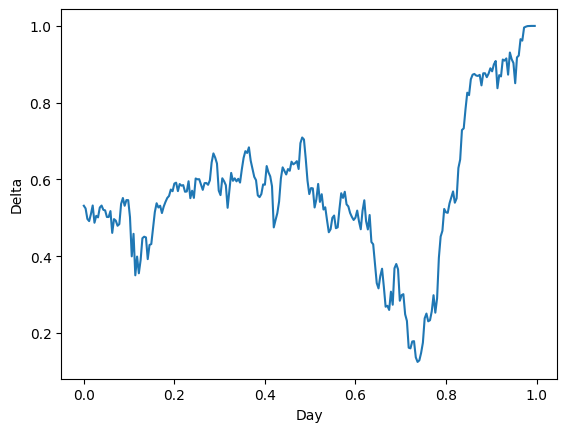

In [33]:
delta_DAX = np.zeros(255)

for i in range(len(delta_DAX)):
    delta_DAX[i] = delta_call_BS(t = t[i], St = DAX[i], K = 16000, T = 1, r = 0.03316, sigma = sigma1)

#print(delta_DAX)

plt.plot(t, delta_DAX)
plt.xlabel('Day')
plt.ylabel('Delta')
plt.show()

### Uncomment and execute the following line only if you obtained no result:
#delta_DAX1 = np.loadtxt('../shared_materials/objects/2_4_4.txt')
#print(delta_DAX1)

#print(np.round(delta_DAX, 15) == np.round(delta_DAX1, 15))
# Interpretation: ...

Since the hedging portfolio can not be rebalanced continuously in reality, we have to rebalance it once every day: The investor makes sure at every day $t_i$ to hold $\delta(t_i)$ shares of the stock. The necessary money to fund these purchases are drawn from the bond investment to make the portfolio self-financing.

**Task 4.5**: Define two arrays `stock_investment` and `bond_investment` of length 255 containing zeros. Fill the first entry of the two arrays by the initial investment of the replicating portfolio in the stock and in the bond, given by $\varphi_1(0) S(0) = \delta(0) S(0)$ and $\varphi_0(0) B(0) = V(0) - \varphi_1(0)S(0)$, respectively.

*Useful Python commands*: `np.zeros`

In [36]:
stock_investment = np.zeros(255)
bond_investment = np.zeros(255)
stock_investment[0] = delta_DAX[0] * DAX[0]
bond_investment[0] = call_prices_DAX[0] - stock_investment[0]

print(stock_investment[0])
print(bond_investment[0])

### Uncomment and execute the following line only if you obtained no result:
# stock_investment[0], bond_investment[0] = 8243.82320380744, -7445.818987905784

8243.82320380744
-7445.818987905784


**Task 4.6**: Use a for-loop to successively calculate the following entries of `stock_investment` and `bond_investment` at the remaining time points $t_i \in \{\frac{1}{255}, \frac{2}{255}, \dots, \frac{254}{255}\}$. The stock investment at time $t_i$ is given by $\delta(t_i) S(t_i)$. The current bond investment $b(t_i)$ at time $t_i$ is given by $b(t_i) = b(t_{i-1}) e^{r \Delta t} - (\delta(t_i) - \delta(t_{i-1})) S(t_i)$.

In [40]:
t = np.arange(255) / 255
M = 1000
r = 0.03316
delta_t = T / M
for i in range(1, 255):
    stock_investment[i] = delta_DAX[i] * DAX[i]
    bond_investment[i] = bond_investment[i - 1] * np.exp(r * (t[i] - t[i-1])) - (delta_DAX[i] - delta_DAX[i - 1]) * DAX[i]

print(stock_investment)
print(bond_investment)

### Uncomment and execute the following line only if you obtained no result:
stock_investment1, bond_investment1 = np.loadtxt('../shared_materials/objects/2_4_6.txt')
#print(np.round(stock_investment, 10) == np.round(stock_investment1, 10))
#print(bond_investment, bond_investment1)
print(np.round(bond_investment, 10) == np.round(bond_investment1, 10))

[ 8243.82320381  8116.47909153  7630.1968669   7530.59755236
  7857.51727079  8261.64480051  7458.76159114  7780.15941505
  7710.22709     8169.96727401  8264.72198027  8064.60171784
  8040.55613174  7733.97377274  7734.48426376  8011.12083982
  7009.30447328  7640.9871264   7571.49588982  7337.23043067
  7413.48129579  8356.25080826  8636.33736638  8270.01583389
  8540.0023785   8538.39749744  7743.52253313  5979.92512468
  6983.13866009  5161.87495738  5974.45416213  5252.29437831
  5829.27495557  6792.28440535  6861.55688223  6829.4833142
  5870.53055375  6494.7187038   6538.45521829  7246.44262292
  7996.33174642  8409.40157755  8212.0274498   8293.96545602
  7954.99016804  8256.59081001  8478.09444995  8665.08996788
  8762.14703685  9069.39897144  8991.01142495  9360.2359176
  9405.33018928  8998.48691078  9339.90179324  9262.54177951
  9290.18883902  8972.52850823  8985.56569779  9478.92280694
  8670.02754546  9026.88313441  8686.16710242  9617.16874112
  9578.51826581  9584.4896

**Task 4.7**: Plot the whole portfolio value (i.e. the sum of the stock investment and the bond investment) against time. In the same plot window, plot the option prices stored in the array `call_prices_DAX`. Interpret your result using a comment. Why does the portfolio not replicate the option perfectly even though an option can theoretically be hedged perfectly in the Black&ndash;Scholes model?


<details>
  <summary>Result:</summary>

> <img src="../shared_materials/images/2_4_7.png" width="550"><details>
  <summary>Interpretation:</summary> 
Since the Black&ndash;Scholes model is complete (i.e. there exists a unique equivalent martingale measure in the model), options can theoretically be perfectly hedged. The fact that the hedging portfolio still deviates over time from the option price originates from two sources of error: First, there is a discretization error. A perfect hedging portfolio in the Black&ndash;Scholes model would require a continuous rebalancing of the portfolio over time, which is in practice not possible. Since we rebalanced our portfolio quite frequently (once a day), the discretization error is not too large in this example. Second, there is a model error. A perfect hedge in the Black&ndash;Scholes model would only be possible if the underlying of the option perfectly followed the stochastic dynamics of the Black-Scholes model, which is a geometric Brownian motion (GBM). However, since the DAX cannot be modeled perfectly by a GBM, perfect hedging is out of reach even if one could theoretically rebalance the hedging portfolio continuously over time to eliminate the discretization error.

 </details>
</details>

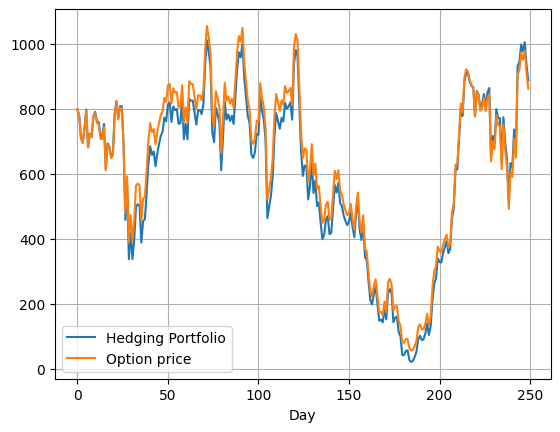

In [41]:
plt.plot(t * 250, stock_investment + bond_investment, label = "Hedging Portfolio")
plt.plot(t * 250, call_prices_DAX, label = "Option price")
plt.xlabel('Day')
plt.grid()
plt.legend()
plt.show()

# Interpretation: ...

The delta of an option can also easily be calculated using the pricing-by-integration approach, which has the advantage that one can thus calculate the delta of options with exotic payoffs in the Black&ndash;Scholes model. One has to differentiate the option price
\begin{equation} V(t) = \frac{1}{\sqrt{2\pi}} \int_{-\infty}^\infty f\Big( S(t) \exp\Big(\big(r - \sigma^2/2\big)(T-t) + \sigma\sqrt{T-t}x\Big)\Big) e^{-r(T-t)} e^{-\frac{x^2}{2}} dx
\end{equation}
by $S(t)$. Assuming that $f$ is differentiable almost everywhere with derivative $f'$ and that differentiation and integration can be interchanged, one obtains
\begin{equation} \frac{\partial}{\partial S(t)}V(t) = \frac{1}{\sqrt{2\pi}} \int_{-\infty}^\infty f'\Big( S(t) \exp\Big(\big(r - \sigma^2/2\big)(T-t) + \sigma\sqrt{T-t}x\Big)\Big) \exp\Big(-\frac{\sigma^2}{2}(T-t) + \sigma\sqrt{T-t}x\Big) e^{-\frac{x^2}{2}} dx.
\end{equation}

**Task 4.8 (Optional)**: Write a function `delta_int(t, f, f_prime, St, T, r, sigma)` that takes the payoff `f` and its derivative `f_prime` as function of $S(T)$ as an input, and then calculates the delta of the option with payoff $f$ by computing the above integral numerically.

In [42]:
from scipy.integrate import quad

def delta_int(t, f, f_prime, St, T, r, sigma):
    def integrand(x):
        ST = St * np.exp((r - (sigma ** 2)/2) * (T - t) + sigma * np.sqrt(T - t) * x)
        return f_prime(ST) * np.exp(- (sigma**2)/2 * (T - t) + sigma * np.sqrt(T - t) * x) * np.exp(-(x ** 2)/2)
    
    return 1 / np.sqrt(2 * np.pi) * quad(integrand, -np.inf, np.inf)[0]

K = 100
f_call = lambda x: np.maximum(x - K, 0)

def f_prime(x, K = 100):
    if x > K:
        return 1
    else:
        return 0

print(delta_int(0, f_call, f_prime, St = 120, T = 1, r = 0.02, sigma = 0.3))


0.7951453161369068


In [43]:
#import numpy as np

#def f_primecoba(x, y):
#    return x**2 * y + np.sin(x*y)

#def partial_x(f, x, y, h=1e-5):
#    return (f(x + h, y) - f(x - h, y)) / (2*h)

#def partial_y(f, x, y, h=1e-5):
#    return (f(x, y + h) - f(x, y - h)) / (2*h)

#print(partial_x(f, 1, 2))
#print(partial_y(f, 1, 2))

In [44]:
#def delta_int(t, f, f_prime, St, T, r, sigma):
#    def integrand(x):
#        ST = St * np.exp((r - (sigma ** 2)/2) * (T - t) + sigma * np.sqrt(T - t) * x)
#        return f_prime(ST) * np.exp(-(x ** 2)/2)
    
#    return (np.exp(- (sigma ** 2)/2) * (T - t) + sigma * np.sqrt(T - t) * x) / np.sqrt(2 * np.pi) * quad(integrand, -np.inf, np.inf)[0]

#print(delta_int(0, f_call, f_prime, St = 120, T = 1, r = 0.02, sigma = 0.3))
### Uncomment and execute the following line only if you obtained no result:
# delta_int = types.FunctionType(marshal.load(open('../shared_materials/objects/2_4_8.mar', 'rb')), globals())

**Task 4.9 (Optional)**: Test your function `delta_int` for a European call option at time $t=0$ with all other input variables as specified at the beginning of the notebook and compare the result to the theoretical result obtained by evaluating the function `delta_call_BS`. 

In [45]:
#r = 0.02
#sigma = 0.3
#T = 1
#K = 100
#S0 = 120

delta_int_result = delta_int(0, f_call, f_prime, St = 120, T = 1, r = 0.02, sigma = 0.3)
delta_call_BS_result = delta_call_BS(t = 0, St = 120, K = 100, T = 1, r = 0.02, sigma = 0.3)

print(delta_int_result)
print(delta_call_BS_result)

0.7951453161369068
0.7951453163680976


<br><br>

## Step 5: Valuation of perpetual American put options

A perpetual American put option is an option contract without expiry that yields the payoff $g(S(t)) = (K − S(t))^+$ at any future time chosen by the holder of the option. Let $x^∗ = \frac{2Kr}{2r+\sigma^2}$. One can show that the value function $v(S(t))$ of the perpetual American put option in the Black&ndash;Scholes model is independent of time and satisfies the boundary problem 
\begin{align} \frac{\sigma^2}{2}x^2 \frac{\partial^2}{\partial x^2} v(x) + rx \frac{\partial}{\partial x}v(x) - rv(x) = 0 \text{ for } x \geq x^*, \\ v(x) = g(x) \text{ for } x \leq x^*. \end{align}

Our goal is to solve this boundary problem numerically using scipy.

**Task 5.1**: Define an array `S_grid` that contains 200 equally spaced points between $10^{-6}$ and `S_max = 200`. Define another array `v_grid` of the same shape as `S_grid` containing zeros. `v_grid` is the array that will in the following tasks be filled with the values $v(S(0))$ of the perpetual American put option for $S(0)$ taking values in `S_grid`. Define also a variable `x_star` containing the value $x^*$ for $K$, $r$ and $\sigma$ as defined at the top of this notebook. Fill all components in `v_grid` that correspond to stock prices $S(0) \leq x^*$ in `S_grid` using the condition $v(x) = g(x) \text{ for } x \leq x^*$ from the boundary problem.

*Useful Python commands*: `np.linspace`, `np.zeros`, `np.zeros_like`, `np.maximum`

In [46]:
S_grid = np.linspace(10 ** (-6), 200, 201)
#print(S_grid)
v_grid = np.zeros(201)
# print(len(v_grid))

r = 0.02
sigma = 0.3
T = 1
K = 100
S0 = 120

x_star = (2 * K * r) / (2 * r + sigma ** 2)
print(x_star) # 30.769230769230766

g3 = lambda S: np.maximum(K - S, 0)  # European Put

for i in range(len(v_grid)):
    if S_grid[i] <= x_star :
        v_grid[i] = g3(S_grid[i])

print(v_grid)

### Uncomment and execute the following lines only if you obtained no result:
S_grid1, v_grid1 = np.loadtxt('../shared_materials/objects/2_5_1.txt')
# x_star = 30.769230769230766

#print(v_grid1)

print(np.array_equal(S_grid, S_grid1)) # True
print(np.array_equal(v_grid, v_grid1)) # True

30.769230769230766
[99.999999   98.99999901 97.99999901 96.99999902 95.99999902 94.99999902
 93.99999903 92.99999904 91.99999904 90.99999904 89.99999905 88.99999906
 87.99999906 86.99999906 85.99999907 84.99999908 83.99999908 82.99999908
 81.99999909 80.99999909 79.9999991  78.99999911 77.99999911 76.99999911
 75.99999912 74.99999913 73.99999913 72.99999913 71.99999914 70.99999915
 69.99999915  0.          0.          0.          0.          0.
  0.          0.          0.          0.          0.          0.
  0.          0.          0.          0.          0.          0.
  0.          0.          0.          0.          0.          0.
  0.          0.          0.          0.          0.          0.
  0.          0.          0.          0.          0.          0.
  0.          0.          0.          0.          0.          0.
  0.          0.          0.          0.          0.          0.
  0.          0.          0.          0.          0.          0.
  0.          0.          0.   

scipy is only capable of numerically solving first-order ordinary differential equations (ODE), i.e. ODEs containing only first but no second derivatives. Luckily, we can transform the second-order ODE from the boundary problem above into a 2-dimensional system of first-order ODEs by setting $v_1 := v$, $v_2 := \frac{\partial}{\partial x}v(x)$ and writing
\begin{equation} \frac{\partial}{\partial x} \begin{pmatrix} v_1(x) \\ v_2(x) \end{pmatrix} = \begin{pmatrix} v_2(x) \\ \frac{2r}{\sigma^2 x^2} [v_1(x) - x v_2(x)] \end{pmatrix} \end{equation}

**Task 5.2**: Write a function `ode_fun(x, v)` that takes a scalar `x` and a size-2 numpy array `v` with components $v_1$ and $v_2$ as inputs and returns a size-2 numpy array representing the right hand side of the above first-order system of ODEs.

In [47]:
v = [1234123, 213]

def ode_fun(x, v):
#    v[0] = v2
#    v[1] = ((2 * r)/ ((sigma ** 2) * (x ** 2))) * (v1 - x * v2)

    v1 = v[0]
    v2 = v[1]
    dv1_dx = v2
    dv2_dx = ((2 * r)/ ((sigma ** 2) * (x ** 2))) * (v1 - x * v2)

    return [dv1_dx, dv2_dx]

#    return v
    
print(ode_fun(71324, v))

### Uncomment and execute the following line only if you obtained no result:
ode_fun1 = types.FunctionType(marshal.load(open('../shared_materials/objects/2_5_2.mar', 'rb')), globals())
#print(v)
#print(ode_fun1(71324, v)) # [ 1.23490000e+04 -7.25341889e-02]
#print(v)

[213, -0.0012194551706418055]


**Task 5.3**: Use the scipy.integrate function `solve_ivp` to solve the 2-dimensional system of first-order ODEs represented by your function `ode_fun` for $x \geq x^*$. To get a smooth solution, use the starting values $v_1(x^*) = g(x^*)$ and $v_2(x^*) = -1$. Fill the entries of `v_grid` corresponding to $S(0) \geq x^*$ with the obtained solution of ODE.

*Useful Python commands* To solve a system of ODEs represented by a function `dy / dt = ode_fun(t, y)` with initial condition `y(t0) = y0` on the interval `(t0, t_end)` and then return the solution evaluated on a grid of points `t_eval` one can use the command `solve_ivp(fun=ode_fun, t_span=(t0, t_end), y0=y0, t_eval=t_eval).y`.

In [48]:
from scipy.integrate import solve_ivp
v_grid_init = np.zeros(201)

v1 = g3(x_star)
v2 = -1

y0 = [K - x_star, -1] # Starting values

# Only take S0 >= x_star
mask = S_grid > x_star
S_eval = S_grid[mask]

# Solve ODE once
sol = solve_ivp(fun = ode_fun, t_span = (x_star, S_grid.max()), y0 = y0, t_eval=S_eval)

v_grid_init[mask] = sol.y[0]
    
print(v_grid_init)


### Uncomment and execute the following line only if you obtained no result:
v_grid1 = np.loadtxt('../shared_materials/objects/2_5_3.txt')
print(v_grid1)

[ 0.          0.          0.          0.          0.          0.
  0.          0.          0.          0.          0.          0.
  0.          0.          0.          0.          0.          0.
  0.          0.          0.          0.          0.          0.
  0.          0.          0.          0.          0.          0.
  0.         69.00124157 68.03443451 67.11030737 66.22547497 65.37723006
 64.56335218 63.78173149 63.03036877 62.30737543 61.6109735  60.93949565
 60.29138516 59.66519595 59.05959256 58.47335014 57.90535449 57.35460203
 56.8201998  56.30136546 55.7974273  55.30782426 54.83210586 54.36981789
 53.91990675 53.4817916  53.05501796 52.63914548 52.23374798 51.83841341
 51.45274387 51.07635563 50.70887909 50.34995881 49.99925347 49.65643594
 49.32119321 48.99322644 48.6722509  48.35799606 48.05020549 47.74863696
 47.45306233 47.16326766 46.87905313 46.60023308 46.32663598 46.05810449
 45.79449536 45.53567955 45.28154212 45.0319823  44.78691348 44.54626316
 44.30984202 44.07

In [49]:
Index_greater_than_Xstar = S_grid > x_star
S_eval = S_grid[Index_greater_than_Xstar]

y0 = [K - x_star, -1]

res = solve_ivp(fun=ode_fun, t_span=(x_star, S_grid.max()), y0 = y0, t_eval = S_eval)
v_grid[Index_greater_than_Xstar] = res.y[0]

print(v_grid)

[99.999999   98.99999901 97.99999901 96.99999902 95.99999902 94.99999902
 93.99999903 92.99999904 91.99999904 90.99999904 89.99999905 88.99999906
 87.99999906 86.99999906 85.99999907 84.99999908 83.99999908 82.99999908
 81.99999909 80.99999909 79.9999991  78.99999911 77.99999911 76.99999911
 75.99999912 74.99999913 73.99999913 72.99999913 71.99999914 70.99999915
 69.99999915 69.00124157 68.03443451 67.11030737 66.22547497 65.37723006
 64.56335218 63.78173149 63.03036877 62.30737543 61.6109735  60.93949565
 60.29138516 59.66519595 59.05959256 58.47335014 57.90535449 57.35460203
 56.8201998  56.30136546 55.7974273  55.30782426 54.83210586 54.36981789
 53.91990675 53.4817916  53.05501796 52.63914548 52.23374798 51.83841341
 51.45274387 51.07635563 50.70887909 50.34995881 49.99925347 49.65643594
 49.32119321 48.99322644 48.6722509  48.35799606 48.05020549 47.74863696
 47.45306233 47.16326766 46.87905313 46.60023308 46.32663598 46.05810449
 45.79449536 45.53567955 45.28154212 45.0319823  44

**Task 5.4**: Plot the perpetual American put option prices from the array `v_grid` against the stock prices from the array `S_grid`. Define also an array `v_grid_EU` that contains the European put option prices at $t=0$ in the Black&ndash;Scholes model corresponding to the values of $S(0)$ from the array `S_grid` and all other variables as before. Plot these European put prices in the same plot. Interpret your result using a comment.

<details>
  <summary>Result:</summary>

> <img src="../shared_materials/images/2_5_4.png" width="550"><details>
  <summary>Interpretation:</summary> 
For large values of $S$ the European put option with strike $K = 100$ and time-to-maturity of 1 year is basically worthless because the probability of the put option expiring in the money (i.e. $S(T) < 100$) becomes infinitesimally small. For the perpetual American put option, the situation is quite different. The optimal exercise barrier for this option is given by $x^* \approx 30.77$, i.e. once the stock price falls below $x^*$, it is optimal to immediately exercise the option. As one can show, the stock price process in the Black&ndash;Scholes model (i.e. the geometric Brownian motion) falls below $x^*$ at some future point with probability 1, no matter the initial stock price $S(0)$. Therefore, the payoff of the perpetual American put at the time of exercise is always given by $(K - x^*)^+ \approx 69.23$. Still, the value of the perpetual put changes with $S(0)$ because it is uncertain when the event of $S(t)$ falling below $x^*$ takes place. As $S(0)$ grows, the optimal exercise time $\tau^*$ grows on average as well, so the shrinking (expected) discount factor $E_Q(e^{-r\tau^*})$ squishes the perpetual put price towards 0. 
    

 </details>
</details>

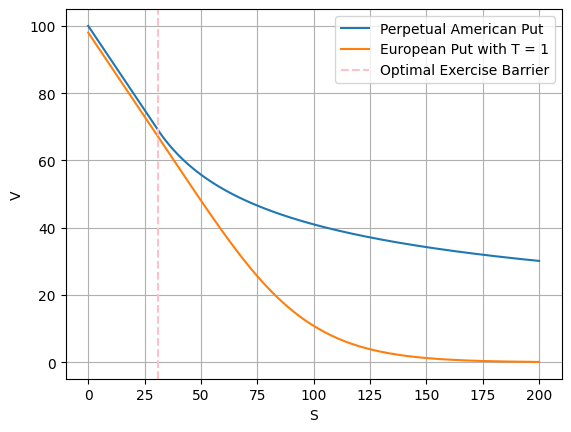

In [36]:
v_grid_EU = european_BS(0, S_grid, K, T, r, sigma, 0)
plt.plot(S_grid, v_grid, label = "Perpetual American Put")
plt.plot(S_grid, v_grid_EU, label = "European Put with T = 1")
plt.axvline(x=x_star, linestyle='--', color='pink', label = "Optimal Exercise Barrier")
plt.xlabel('S')
plt.ylabel('V')
plt.grid()
plt.legend()
plt.show()

# Interpretation: ...